# WikiBio Golden Layer Analysis

This notebook analyzes layer performance for WikiBio dataset with proper metric handling:
- **Rewrite Accuracy**: Edit success rate
- **Locality**: Relation specificity (average)
- **Fluency**: ngram_entropy (NEGATED - lower is better)
- **Overall**: Normalized average of all three metrics

In [23]:
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
import pandas as pd

plt.style.use('seaborn-v0_8-darkgrid')

## 1. Load WikiBio Data

WikiBio has a nested JSON structure that needs special handling.

In [24]:
def load_wikibio_data(data_dir='../allLayerPerformance', n_layers=64):
    """
    Load WikiBio results from nested JSON files.
    
    Structure:
    {
      "post": {
        "rewrite_acc": [score],
        "locality": {"Relation_Specificity_acc": [scores...]},
        "fluency": {"ngram_entropy": value}
      }
    }
    """
    data_dir = Path(data_dir)
    
    # Storage for all layer data
    all_data = defaultdict(list)  # layer -> list of samples
    
    # Load all JSON files
    for layer in range(n_layers):
        layer_samples = []
        
        # Find all files for this layer
        for json_file in sorted(data_dir.glob(f"*_layer{layer}.json")):
            with open(json_file, 'r') as f:
                samples = json.load(f)
                
            for sample in samples:
                if 'post' not in sample:
                    continue
                    
                post = sample['post']
                
                # Extract metrics
                sample_data = {}
                
                # Rewrite accuracy
                if 'rewrite_acc' in post and isinstance(post['rewrite_acc'], list):
                    sample_data['rewrite_acc'] = post['rewrite_acc'][0]
                else:
                    sample_data['rewrite_acc'] = np.nan
                
                # Locality (Relation Specificity) - average the scores
                if ('locality' in post and 
                    'Relation_Specificity_acc' in post['locality']):
                    locality_scores = post['locality']['Relation_Specificity_acc']
                    if isinstance(locality_scores, list) and len(locality_scores) > 0:
                        sample_data['locality_acc'] = np.mean(locality_scores)
                    else:
                        sample_data['locality_acc'] = np.nan
                else:
                    sample_data['locality_acc'] = np.nan
                
                # Fluency (ngram_entropy)
                if ('fluency' in post and 
                    'ngram_entropy' in post['fluency']):
                    sample_data['fluency'] = post['fluency']['ngram_entropy']
                else:
                    sample_data['fluency'] = np.nan
                
                layer_samples.append(sample_data)
        
        all_data[layer] = layer_samples
    
    # Determine number of samples (max across all layers)
    n_samples = max(len(samples) for samples in all_data.values())
    
    # Convert to tensors (samples x layers)
    results = {}
    metrics = ['rewrite_acc', 'locality_acc', 'fluency']
    
    for metric in metrics:
        # Initialize tensor
        tensor = torch.full((n_samples, n_layers), float('nan'))
        
        # Fill with data
        for layer in range(n_layers):
            layer_samples = all_data[layer]
            for sample_idx, sample in enumerate(layer_samples):
                if sample_idx < n_samples:
                    tensor[sample_idx, layer] = sample.get(metric, np.nan)
        
        results[metric] = tensor
    
    print(f"\nLoaded WikiBio data:")
    print(f"  Samples: {n_samples}")
    print(f"  Layers: {n_layers}")
    for metric, tensor in results.items():
        non_nan = (~torch.isnan(tensor)).sum().item()
        total = tensor.numel()
        print(f"  {metric}: {non_nan}/{total} non-NaN values")
    
    return results, n_samples, n_layers

# Load data
results, n_samples, n_layers = load_wikibio_data()


Loaded WikiBio data:
  Samples: 306
  Layers: 64
  rewrite_acc: 19584/19584 non-NaN values
  locality_acc: 19584/19584 non-NaN values
  fluency: 19584/19584 non-NaN values


## 2. Compute Overall Metric

**IMPORTANT**: Fluency (ngram_entropy) - lower is better, so we negate it before normalization.

In [25]:
def compute_overall_samplewise(results, eps=1e-10):
    """
    Compute overall metric per (sample, layer):

    For EACH sample:
      1. Negate fluency
      2. Min-max normalize EACH METRIC across layers
      3. Average normalized metrics
    """

    # Step 1: negate fluency
    fluency_neg = -results['fluency']

    normalized = {}

    for metric_name, tensor in [
        ('rewrite_acc', results['rewrite_acc']),
        ('locality_acc', results['locality_acc']),
        ('fluency_neg', fluency_neg),
    ]:
        # tensor shape: [samples, layers]

        # Mask NaNs
        valid = ~torch.isnan(tensor)

        # Prepare min/max
        t_min = tensor.clone()
        t_max = tensor.clone()
        t_min[~valid] = float('inf')
        t_max[~valid] = float('-inf')

        # Min/max ACROSS LAYERS (dim=1)
        min_vals = t_min.min(dim=1, keepdim=True).values
        max_vals = t_max.max(dim=1, keepdim=True).values

        denom = max_vals - min_vals

        # Normalize with neutral fallback
        norm = torch.where(
            denom > eps,
            (tensor - min_vals) / denom,
            torch.full_like(tensor, 0.0)
        )

        norm[~valid] = float('nan')
        normalized[metric_name] = norm

    # Step 3: average normalized metrics
    overall = (
        normalized['rewrite_acc'] +
        normalized['locality_acc'] +
        normalized['fluency_neg']
    ) / 3.0

    results['overall'] = overall
    return results

# Compute overall metric
results = compute_overall_samplewise(results)

## 3. Split into Proxy and Test Sets

In [26]:
def split_dataset(results, n_samples, proxy_size=30, random_seed=42):
    """Split into proxy and test sets"""
    torch.manual_seed(random_seed)
    indices = torch.randperm(n_samples)
    
    proxy_indices = indices[:proxy_size]
    test_indices = indices[proxy_size:]
    
    # Compute means for each set
    proxy_means = {}
    test_means = {}
    
    for metric, values in results.items():
        proxy_means[metric] = values[proxy_indices].nanmean(dim=0)
        test_means[metric] = values[test_indices].nanmean(dim=0)
    
    print(f"\nDataset split:")
    print(f"  Proxy set: {len(proxy_indices)} samples")
    print(f"  Test set: {len(test_indices)} samples")
    
    return proxy_means, test_means, proxy_indices, test_indices

proxy_means, test_means, proxy_indices, test_indices = split_dataset(
    results, n_samples, proxy_size=30
)


Dataset split:
  Proxy set: 30 samples
  Test set: 276 samples


## 3a. Specific Layer Performance Analysis

Analyze performance at a specific layer of interest across different sample ranges.

In [27]:
# Analyze a specific layer (e.g., layer 17)
layer_idx = 17

print(f"{'='*70}")
print(f"LAYER {layer_idx} PERFORMANCE ANALYSIS")
print(f"{'='*70}")

# Define metrics info
metrics_info = [
    ('rewrite_acc', 'Rewrite Accuracy'),
    ('locality_acc', 'Locality'),
    ('fluency', 'Fluency (raw)'),
    ('overall', 'Overall')
]

# Analyze different sample ranges if dataset is large enough
if n_samples >= 300:
    print(f"\nFirst 300 samples (indices 0-299):")
    for metric_key, metric_name in metrics_info:
        layer_values = results[metric_key][:300, layer_idx]
        valid_values = layer_values[~torch.isnan(layer_values)]
        if len(valid_values) > 0:
            mean_val = valid_values.mean().item()
            print(f"  {metric_name:20s}: {mean_val:.4f} (n={len(valid_values)})")
        else:
            print(f"  {metric_name:20s}: No valid data")

print(f"\nAll {n_samples} samples:")
for metric_key, metric_name in metrics_info:
    layer_values = results[metric_key][:, layer_idx]
    valid_values = layer_values[~torch.isnan(layer_values)]
    if len(valid_values) > 0:
        mean_val = valid_values.mean().item()
        print(f"  {metric_name:20s}: {mean_val:.4f} (n={len(valid_values)})")
    else:
        print(f"  {metric_name:20s}: No valid data")

LAYER 17 PERFORMANCE ANALYSIS

First 300 samples (indices 0-299):
  Rewrite Accuracy    : 0.9534 (n=300)
  Locality            : 0.7207 (n=300)
  Fluency (raw)       : 5.5679 (n=300)
  Overall             : 0.6013 (n=300)

All 306 samples:
  Rewrite Accuracy    : 0.9530 (n=306)
  Locality            : 0.7172 (n=306)
  Fluency (raw)       : 5.5766 (n=306)
  Overall             : 0.5989 (n=306)


## 4. Find Best Layers and Correlations

In [28]:
def analyze_best_layers(proxy_means, test_means):
    """Find best layers and compute correlations"""
    
    analysis = {}
    
    # ALL metrics including fluency
    metrics_info = [
        ('rewrite_acc', 'Rewrite Accuracy'),
        ('locality_acc', 'Locality'),
        ('fluency', 'Fluency (raw - lower is better)'),
        ('overall', 'Overall')
    ]
    
    print("\nBest Layer Analysis:")
    print("="*70)
    
    for metric_key, metric_name in metrics_info:
        if metric_key not in proxy_means or metric_key not in test_means:
            continue
            
        proxy_mean = proxy_means[metric_key]
        test_mean = test_means[metric_key]
        
        # Find best layers (handle NaN values properly)
        # For fluency (raw), LOWER is better, so find MIN instead of MAX
        valid_proxy = ~torch.isnan(proxy_mean)
        valid_test = ~torch.isnan(test_mean)
        
        if metric_key == 'fluency':
            # For fluency: lower is better
            if valid_proxy.sum() > 0:
                proxy_best_val = proxy_mean[valid_proxy].min()  # MIN for fluency
                proxy_best = torch.where(proxy_mean == proxy_best_val)[0].tolist()
            else:
                proxy_best_val = torch.tensor(float('nan'))
                proxy_best = []
            
            if valid_test.sum() > 0:
                test_best_val = test_mean[valid_test].min()  # MIN for fluency
                test_best = torch.where(test_mean == test_best_val)[0].tolist()
            else:
                test_best_val = torch.tensor(float('nan'))
                test_best = []
        else:
            # For other metrics: higher is better
            if valid_proxy.sum() > 0:
                proxy_best_val = proxy_mean[valid_proxy].max()
                proxy_best = torch.where(proxy_mean == proxy_best_val)[0].tolist()
            else:
                proxy_best_val = torch.tensor(float('nan'))
                proxy_best = []
            
            if valid_test.sum() > 0:
                test_best_val = test_mean[valid_test].max()
                test_best = torch.where(test_mean == test_best_val)[0].tolist()
            else:
                test_best_val = torch.tensor(float('nan'))
                test_best = []
        
        overlap = list(set(proxy_best) & set(test_best))
        
        # Compute correlation
        valid_mask = ~(torch.isnan(proxy_mean) | torch.isnan(test_mean))
        if valid_mask.sum() > 1:
            corr = torch.corrcoef(torch.stack([
                proxy_mean[valid_mask],
                test_mean[valid_mask]
            ]))[0, 1].item()
        else:
            corr = np.nan
        
        analysis[metric_key] = {
            'name': metric_name,
            'proxy_best': proxy_best,
            'proxy_score': proxy_best_val.item(),
            'test_best': test_best,
            'test_score': test_best_val.item(),
            'overlap': overlap,
            'correlation': corr
        }
        
        indicator = "(lower is better)" if metric_key == 'fluency' else ""
        print(f"\n{metric_name} {indicator}:")
        print(f"  Proxy: Layers {proxy_best} (score: {proxy_best_val:.4f})")
        print(f"  Test:  Layers {test_best} (score: {test_best_val:.4f})")
        print(f"  Overlap: {overlap if overlap else 'None'}")
        print(f"  Correlation: r = {corr:.4f}")
    
    return analysis

analysis = analyze_best_layers(proxy_means, test_means)


Best Layer Analysis:

Rewrite Accuracy :
  Proxy: Layers [43] (score: 0.9932)
  Test:  Layers [43] (score: 0.9905)
  Overlap: [43]
  Correlation: r = 0.9955

Locality :
  Proxy: Layers [60] (score: 0.9556)
  Test:  Layers [60] (score: 0.9632)
  Overlap: [60]
  Correlation: r = 0.9602

Fluency (raw - lower is better) (lower is better):
  Proxy: Layers [60] (score: 5.5891)
  Test:  Layers [17] (score: 5.5703)
  Overlap: None
  Correlation: r = 0.0283

Overall :
  Proxy: Layers [48] (score: 0.6524)
  Test:  Layers [46] (score: 0.6687)
  Overlap: None
  Correlation: r = 0.9563


## 4a. Average Performance Statistics: Proxy vs Test

Compare average performance across all layers between proxy and test sets.

In [29]:
# Display average performance statistics
print(f"\n{'='*70}")
print("AVERAGE PERFORMANCE: PROXY vs TEST")
print(f"{'='*70}")

for metric_key, metric_name in metrics_info:
    if metric_key in proxy_means and metric_key in test_means:
        proxy_avg = proxy_means[metric_key].nanmean().item()
        test_avg = test_means[metric_key].nanmean().item()
        
        print(f"\n{metric_name}:")
        print(f"  Proxy set (avg across all layers): {proxy_avg:.4f}")
        print(f"  Test set (avg across all layers):  {test_avg:.4f}")
        print(f"  Difference: {abs(proxy_avg - test_avg):.4f}")


AVERAGE PERFORMANCE: PROXY vs TEST

Rewrite Accuracy:
  Proxy set (avg across all layers): 0.8743
  Test set (avg across all layers):  0.8880
  Difference: 0.0136

Locality:
  Proxy set (avg across all layers): 0.7090
  Test set (avg across all layers):  0.7604
  Difference: 0.0514

Fluency (raw):
  Proxy set (avg across all layers): 5.6797
  Test set (avg across all layers):  5.5981
  Difference: 0.0817

Overall:
  Proxy set (avg across all layers): 0.5307
  Test set (avg across all layers):  0.5574
  Difference: 0.0267


## 5. Golden Layer Summary

In [30]:
print("\n" + "="*70)
print("GOLDEN LAYER IDENTIFICATION")
print("="*70)

overall_info = analysis['overall']

print(f"\nProxy best layers:  {overall_info['proxy_best']} (score: {overall_info['proxy_score']:.4f})")
print(f"Test best layers:   {overall_info['test_best']} (score: {overall_info['test_score']:.4f})")

if overall_info['overlap']:
    print(f"\n✓✓✓ GOLDEN LAYER(S) FOUND: {overall_info['overlap']} ✓✓✓")
    print("These layers perform best on both proxy and test sets!")
else:
    print("\n✗ No perfect overlap between proxy and test best layers")
    print("Consider using proxy layers or analyzing correlation.")

# Correlation summary
correlations = [info['correlation'] for info in analysis.values() 
                if not np.isnan(info['correlation'])]

print(f"\nCORRELATION SUMMARY:")
print(f"  Average: {np.mean(correlations):.4f}")
print(f"  Min: {np.min(correlations):.4f}")
print(f"  Max: {np.max(correlations):.4f}")


GOLDEN LAYER IDENTIFICATION

Proxy best layers:  [48] (score: 0.6524)
Test best layers:   [46] (score: 0.6687)

✗ No perfect overlap between proxy and test best layers
Consider using proxy layers or analyzing correlation.

CORRELATION SUMMARY:
  Average: 0.7351
  Min: 0.0283
  Max: 0.9955


## 6. Visualizations

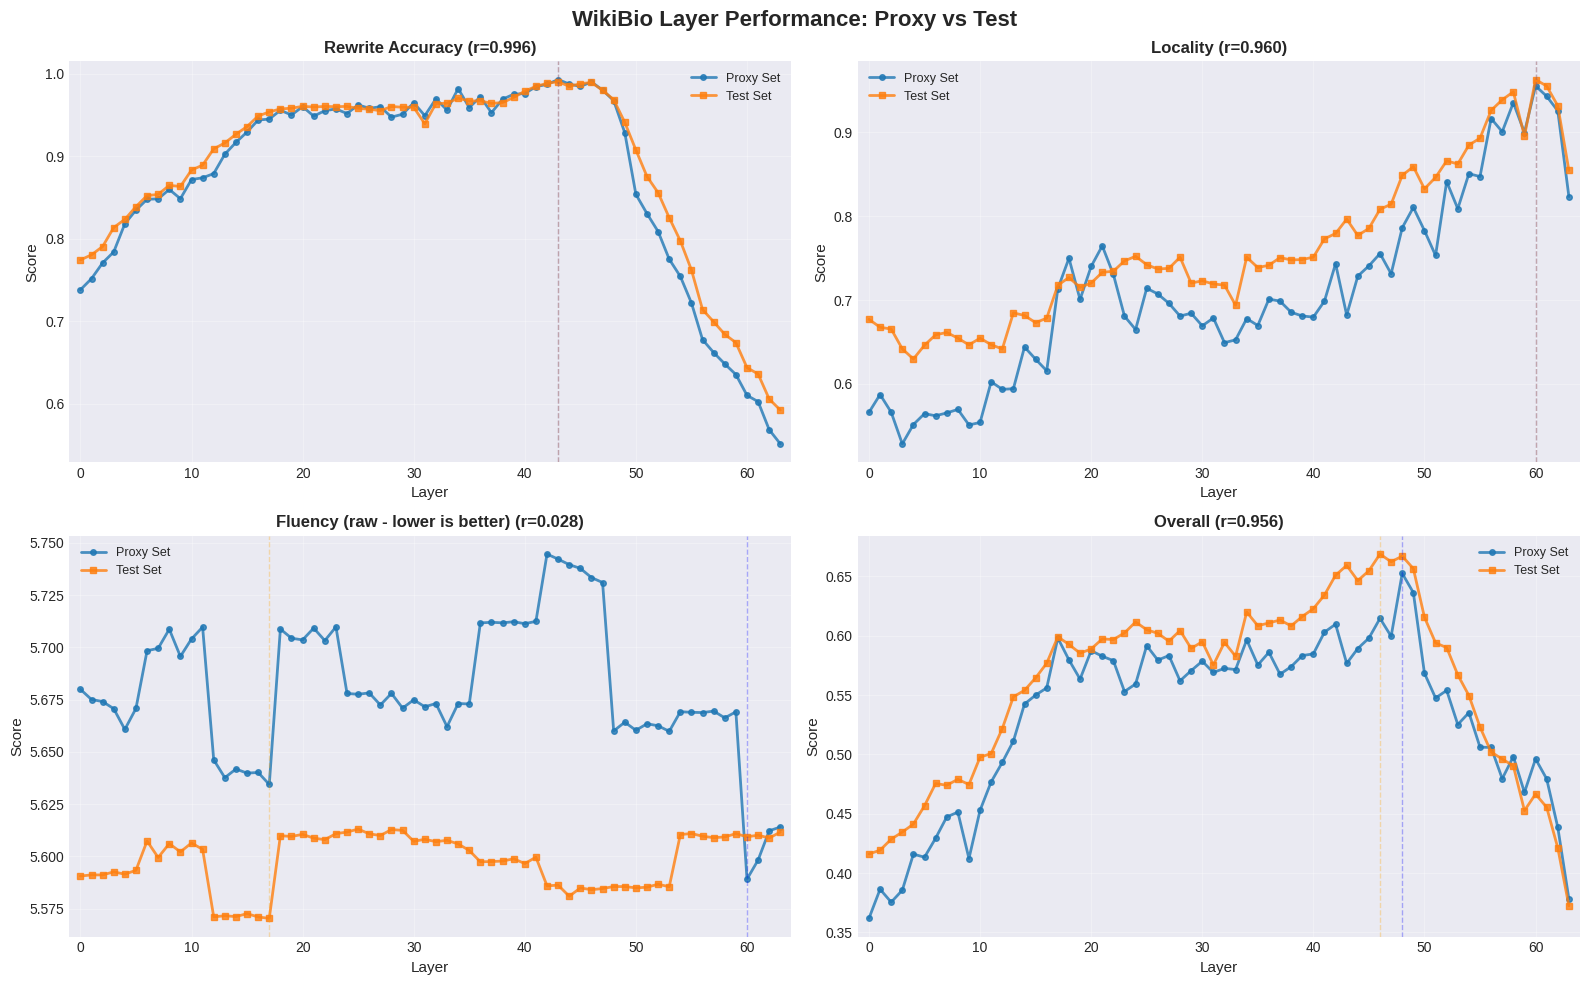

In [31]:
# Plot layer performance curves - ALL 4 metrics
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('WikiBio Layer Performance: Proxy vs Test', fontsize=16, fontweight='bold')
axes = axes.flatten()

layers_array = np.arange(n_layers)

for idx, (metric_key, info) in enumerate(analysis.items()):
    if idx >= 4:
        break
    
    ax = axes[idx]
    metric_name = info['name']
    
    proxy_values = proxy_means[metric_key].numpy()
    test_values = test_means[metric_key].numpy()
    
    # Plot curves
    ax.plot(layers_array, proxy_values, marker='o', linewidth=2, markersize=4,
            label='Proxy Set', alpha=0.8)
    ax.plot(layers_array, test_values, marker='s', linewidth=2, markersize=4,
            label='Test Set', alpha=0.8)
    
    # Mark best layers
    for layer in info['proxy_best']:
        ax.axvline(layer, color='blue', linestyle='--', alpha=0.3, linewidth=1)
    for layer in info['test_best']:
        ax.axvline(layer, color='orange', linestyle='--', alpha=0.3, linewidth=1)
    
    ax.set_xlabel('Layer', fontsize=11)
    ax.set_ylabel('Score', fontsize=11)
    ax.set_title(f"{metric_name} (r={info['correlation']:.3f})", 
                fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-1, n_layers)

plt.tight_layout()
plt.show()

## 7. Bar Chart Comparison

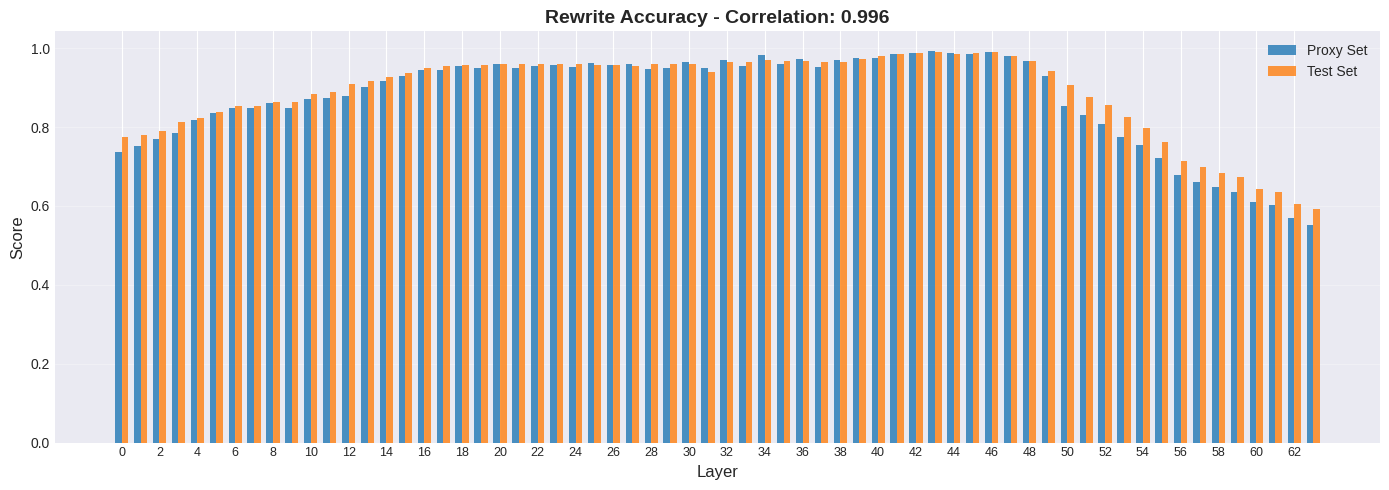

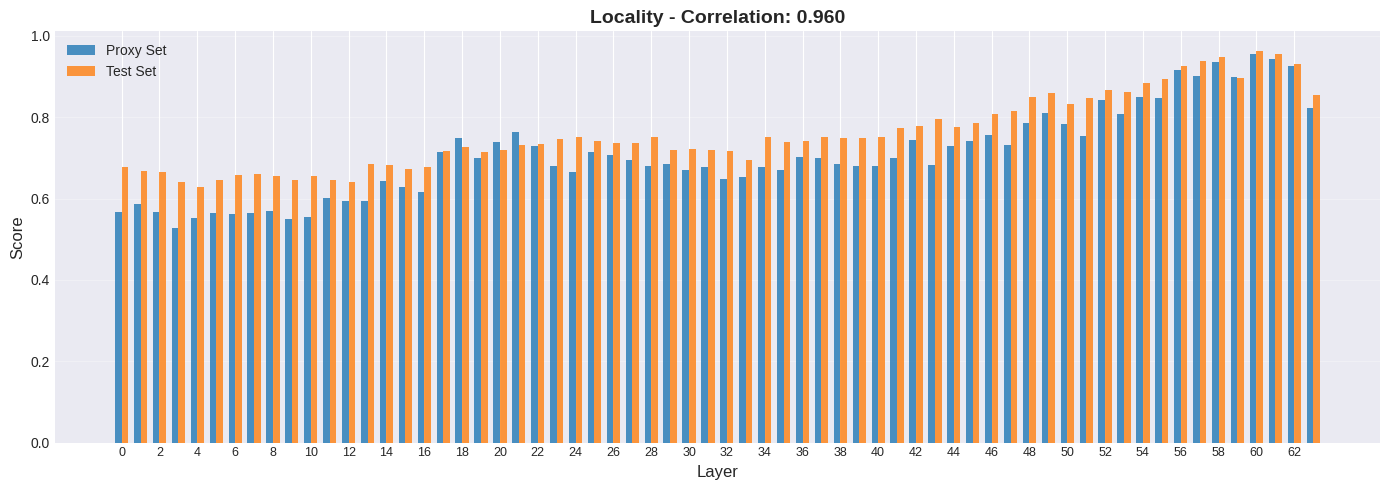

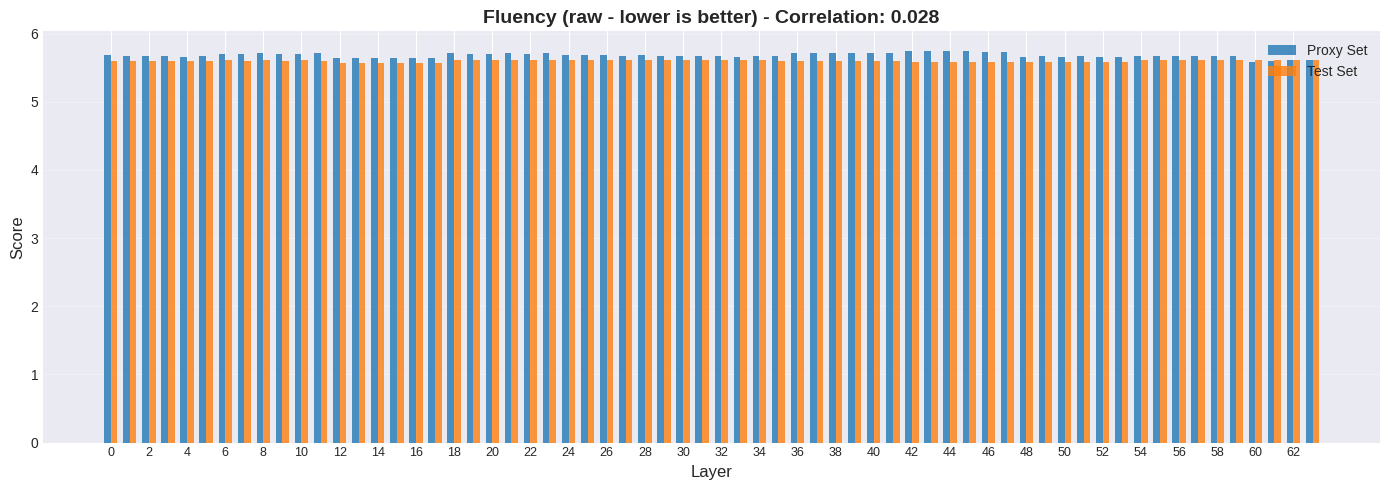

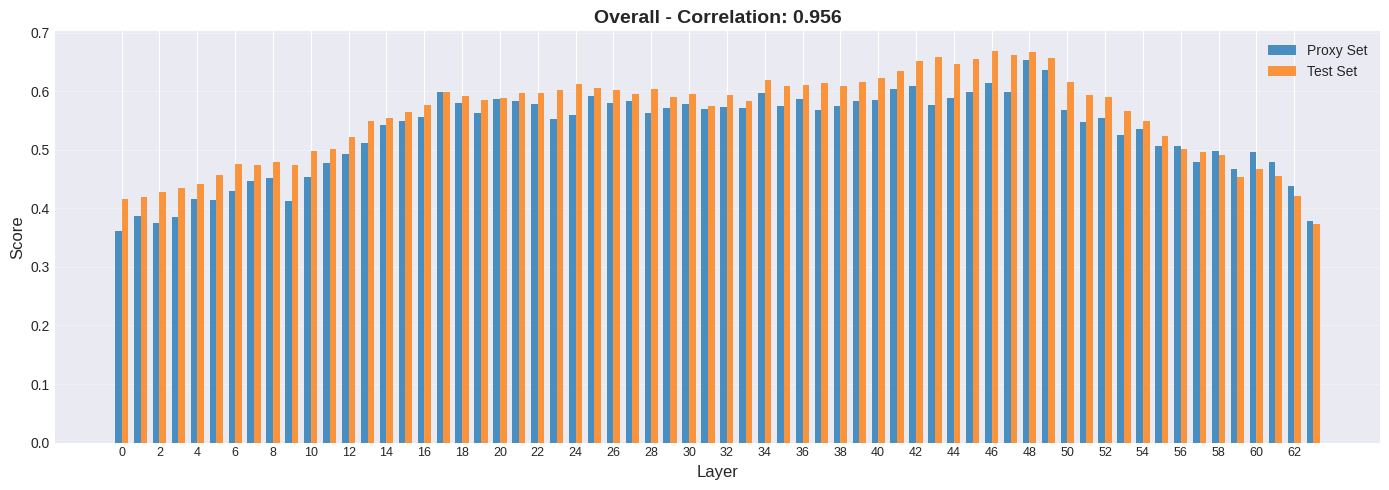

In [32]:
# Bar charts for each metric
for metric_key, info in analysis.items():
    fig, ax = plt.subplots(figsize=(14, 5))
    
    proxy_values = proxy_means[metric_key].numpy()
    test_values = test_means[metric_key].numpy()
    
    x = np.arange(n_layers)
    width = 0.35
    
    ax.bar(x - width/2, proxy_values, width, label='Proxy Set', alpha=0.8)
    ax.bar(x + width/2, test_values, width, label='Test Set', alpha=0.8)
    
    ax.set_xlabel('Layer', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_title(f"{info['name']} - Correlation: {info['correlation']:.3f}",
                fontsize=14, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_xticks(range(0, n_layers, 2))
    ax.set_xticklabels(range(0, n_layers, 2), fontsize=9)
    
    plt.tight_layout()
    plt.show()

## 8. Summary Table

In [33]:
# Create summary DataFrame
summary_data = []

for metric_key, info in analysis.items():
    summary_data.append({
        'Metric': info['name'],
        'Correlation': f"{info['correlation']:.4f}",
        'Proxy Best Layers': str(info['proxy_best']),
        'Proxy Best Score': f"{info['proxy_score']:.4f}",
        'Test Best Layers': str(info['test_best']),
        'Test Best Score': f"{info['test_score']:.4f}",
        'Overlap': str(info['overlap']) if info['overlap'] else 'None'
    })

df_summary = pd.DataFrame(summary_data)
print("\n" + "="*70)
print("SUMMARY TABLE")
print("="*70)
print(df_summary.to_string(index=False))

# Save to CSV
df_summary.to_csv('wikibio_golden_layer_summary.csv', index=False)
print("\nSummary saved to: wikibio_golden_layer_summary.csv")


SUMMARY TABLE
                         Metric Correlation Proxy Best Layers Proxy Best Score Test Best Layers Test Best Score Overlap
               Rewrite Accuracy      0.9955              [43]           0.9932             [43]          0.9905    [43]
                       Locality      0.9602              [60]           0.9556             [60]          0.9632    [60]
Fluency (raw - lower is better)      0.0283              [60]           5.5891             [17]          5.5703    None
                        Overall      0.9563              [48]           0.6524             [46]          0.6687    None

Summary saved to: wikibio_golden_layer_summary.csv


## 9. Detailed Layer Analysis

Examine layers around the golden layer.

In [34]:
# Create enhanced summary table with metrics as columns - ALL 4 metrics
metric_names = ['Rewrite Accuracy', 'Locality', 'Fluency (raw)', 'Overall']
metric_keys = ['rewrite_acc', 'locality_acc', 'fluency', 'overall']
print(analysis["overall"]['proxy_best'][0])
print(analysis["overall"]['test_best'][0])
table_data = {
    'Metric': metric_names,
    'Correlation': [f"{analysis[key]['correlation']:.4f}" if key in analysis else "N/A"
                   for key in metric_keys],
    'Test score of Best layer selected by proxy': [f"{test_means[key][analysis['overall']['proxy_best'][0]].item():.4f}" if key in test_means else "N/A"
                     for key in metric_keys],
    'Layer 5 Test': [f"{test_means[key][5].item():.4f}" if key in test_means else "N/A"
                     for key in metric_keys],
    'Test Score of Best Layer Selected by Test': [f"{test_means[key][analysis['overall']['test_best']][0].item():.4f}" if key in test_means else "N/A"
                     for key in metric_keys],
    'Test Best Layers': [str(analysis[key]['test_best']) if key in analysis else "N/A"
                        for key in metric_keys],
    'Proxy Best Layers': [str(analysis[key]['proxy_best']) if key in analysis else "N/A"
                         for key in metric_keys],
    'Proxy Best Score': [f"{analysis[key]['proxy_score']:.4f}" if key in analysis else "N/A"
                        for key in metric_keys],
    'Test Best Score': [f"{analysis[key]['test_score']:.4f}" if key in analysis else "N/A"
                       for key in metric_keys],
    'Layer 5 Proxy': [f"{proxy_means[key][5].item():.4f}" if key in proxy_means else "N/A"
                      for key in metric_keys],
}

# Add rows for performance at layers selected by each metric (for proxy set)
for selector_key in ['rewrite_acc', 'locality_acc', 'fluency', 'overall']:
    if selector_key in analysis:
        best_layers = analysis[selector_key]['proxy_best']
        if best_layers:
            # Take first layer if there are ties
            layer = best_layers[0]
            selector_name = analysis[selector_key]['name']
            row_name = f'{selector_name} Best Layer Proxy'
            table_data[row_name] = [f"{proxy_means[metric_key][layer].item():.4f}"
                                   if metric_key in proxy_means else "N/A"
                                   for metric_key in metric_keys]

# Add rows for performance at layers selected by each metric (for test set)
for selector_key in ['rewrite_acc', 'locality_acc', 'fluency', 'overall']:
    if selector_key in analysis:
        best_layers = analysis[selector_key]['test_best']
        if best_layers:
            # Take first layer if there are ties
            layer = best_layers[0]
            selector_name = analysis[selector_key]['name']
            row_name = f'{selector_name} Best Layer Test'
            table_data[row_name] = [f"{test_means[metric_key][layer].item():.4f}"
                                   if metric_key in test_means else "N/A"
                                   for metric_key in metric_keys]

df_summary = pd.DataFrame(table_data)
df_transposed = df_summary.set_index('Metric').T

print(f"\n{'='*70}")
print("SUMMARY TABLE (with all 4 metrics)")
print(f"{'='*70}\n")
print(df_transposed.to_string())
print()

# Save to CSV
df_transposed.to_csv('wikibio_golden_layer_summary.csv')
print("Summary saved to: wikibio_golden_layer_summary.csv")

48
46

SUMMARY TABLE (with all 4 metrics)

Metric                                           Rewrite Accuracy Locality Fluency (raw) Overall
Correlation                                                0.9955   0.9602        0.0283  0.9563
Test score of Best layer selected by proxy                 0.9688   0.8488        5.5855  0.6670
Layer 5 Test                                               0.8389   0.6460        5.5933  0.4567
Test Score of Best Layer Selected by Test                  0.9896   0.8083        5.5840  0.6687
Test Best Layers                                             [43]     [60]          [17]    [46]
Proxy Best Layers                                            [43]     [60]          [60]    [48]
Proxy Best Score                                           0.9932   0.9556        5.5891  0.6524
Test Best Score                                            0.9905   0.9632        5.5703  0.6687
Layer 5 Proxy                                              0.8348   0.5643        5.

## Notes

### WikiBio-Specific Handling:
1. **Nested JSON structure**: Extracts from `post.rewrite_acc[0]`, `post.locality.Relation_Specificity_acc` (averaged), `post.fluency.ngram_entropy`
2. **Fluency negation**: Lower fluency is better, so we negate before normalization
3. **Three metrics only**: rewrite_acc, locality_acc, fluency (no portability for WikiBio)
4. **Overall**: Average of three normalized metrics

### Interpretation:
- **Golden Layer**: Layer(s) that perform best on both proxy and test sets
- **High Correlation**: Indicates proxy set is representative of test set
- **Overlap**: Agreement between proxy and test best layers

## 10. Proxy Size Stability Analysis

Analyze how the selected golden layer changes with different proxy sizes.

In [35]:
from collections import Counter

# Test different proxy sizes to see stability
proxy_sizes = list(range(1, min(n_samples, 501)))

proxy_best_layers_scalar = []
test_best_layers_scalar = []

print("Analyzing proxy size stability...")
print(f"Testing proxy sizes from 1 to {len(proxy_sizes)}")

for i, proxy_size in enumerate(proxy_sizes):
    if (i + 1) % 50 == 0:
        print(f"  Progress: {i+1}/{len(proxy_sizes)} proxy sizes tested")
    
    # Split dataset with current proxy size
    torch.manual_seed(42)
    indices = torch.randperm(n_samples)
    
    temp_proxy_indices = indices[:proxy_size]
    temp_test_indices = indices[proxy_size:]
    
    # Skip if test set is too small
    if len(temp_test_indices) < 10:
        continue
    
    # Compute means for overall metric
    proxy_overall = results['overall'][temp_proxy_indices].nanmean(dim=0)
    test_overall = results['overall'][temp_test_indices].nanmean(dim=0)
    
    # Find best layers
    valid_proxy = ~torch.isnan(proxy_overall)
    valid_test = ~torch.isnan(test_overall)
    
    if valid_proxy.sum() > 0:
        proxy_max = proxy_overall[valid_proxy].max()
        proxy_layers = torch.where(proxy_overall == proxy_max)[0].tolist()
    else:
        proxy_layers = []
    
    if valid_test.sum() > 0:
        test_max = test_overall[valid_test].max()
        test_layers = torch.where(test_overall == test_max)[0].tolist()
    else:
        test_layers = []
    
    # Reduce list to scalar using MODE (most common layer)
    if proxy_layers:
        proxy_mode = Counter(proxy_layers).most_common(1)[0][0]
    else:
        proxy_mode = np.nan
    
    if test_layers:
        test_mode = Counter(test_layers).most_common(1)[0][0]
    else:
        test_mode = np.nan
    
    proxy_best_layers_scalar.append(proxy_mode)
    test_best_layers_scalar.append(test_mode)

print(f"\nCompleted: {len(proxy_best_layers_scalar)} data points collected")

Analyzing proxy size stability...
Testing proxy sizes from 1 to 305
  Progress: 50/305 proxy sizes tested
  Progress: 100/305 proxy sizes tested
  Progress: 150/305 proxy sizes tested
  Progress: 200/305 proxy sizes tested
  Progress: 250/305 proxy sizes tested
  Progress: 300/305 proxy sizes tested

Completed: 296 data points collected


## 9a. Proxy Size Comparison (Quick Test)

Compare golden layer identification with different proxy sizes.

In [36]:
# Compare results with different proxy sizes
test_proxy_sizes = [50, 100, 200]

print(f"\n{'='*70}")
print("PROXY SIZE COMPARISON")
print(f"{'='*70}")

for test_size in test_proxy_sizes:
    if test_size >= n_samples:
        print(f"\nProxy size: {test_size} - Skipped (not enough samples)")
        continue
        
    # Split with current proxy size
    torch.manual_seed(42)
    indices = torch.randperm(n_samples)
    
    temp_proxy_indices = indices[:test_size]
    temp_test_indices = indices[test_size:]
    
    # Compute means
    temp_proxy_overall = results['overall'][temp_proxy_indices].nanmean(dim=0)
    temp_test_overall = results['overall'][temp_test_indices].nanmean(dim=0)
    
    # Find best layers
    valid_proxy = ~torch.isnan(temp_proxy_overall)
    valid_test = ~torch.isnan(temp_test_overall)
    
    if valid_proxy.sum() > 0:
        proxy_max = temp_proxy_overall[valid_proxy].max()
        proxy_best = torch.where(temp_proxy_overall == proxy_max)[0].tolist()
    else:
        proxy_best = []
    
    if valid_test.sum() > 0:
        test_max = temp_test_overall[valid_test].max()
        test_best = torch.where(temp_test_overall == test_max)[0].tolist()
    else:
        test_best = []
    
    overlap = list(set(proxy_best) & set(test_best))
    
    # Compute correlation
    valid_mask = ~(torch.isnan(temp_proxy_overall) | torch.isnan(temp_test_overall))
    if valid_mask.sum() > 1:
        corr = torch.corrcoef(torch.stack([
            temp_proxy_overall[valid_mask],
            temp_test_overall[valid_mask]
        ]))[0, 1].item()
    else:
        corr = np.nan
    
    print(f"\nProxy size: {test_size}")
    print(f"  Proxy best layers: {proxy_best}")
    print(f"  Test best layers:  {test_best}")
    print(f"  Overlap: {overlap if overlap else 'None'}")
    print(f"  Correlation: {corr:.4f}")


PROXY SIZE COMPARISON

Proxy size: 50
  Proxy best layers: [48]
  Test best layers:  [46]
  Overlap: None
  Correlation: 0.9767

Proxy size: 100
  Proxy best layers: [48]
  Test best layers:  [46]
  Overlap: None
  Correlation: 0.9873

Proxy size: 200
  Proxy best layers: [48]
  Test best layers:  [46]
  Overlap: None
  Correlation: 0.9831


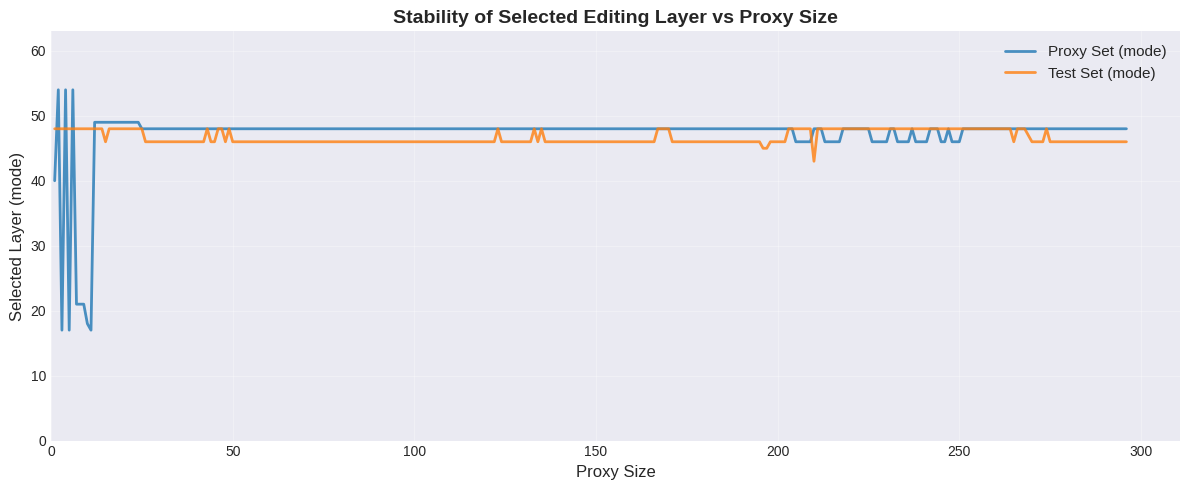


Stability Statistics:
Proxy set:
  Most common layer: 48
  Std deviation: 4.53
  Range: [17, 54]

Test set:
  Most common layer: 46
  Std deviation: 0.98
  Range: [43, 48]


In [37]:
# Plot stability of selected layer vs proxy size
plt.figure(figsize=(12, 5))
plt.plot(proxy_sizes[:len(proxy_best_layers_scalar)], 
         proxy_best_layers_scalar, 
         label='Proxy Set (mode)', 
         linewidth=2, 
         alpha=0.8)
plt.plot(proxy_sizes[:len(test_best_layers_scalar)], 
         test_best_layers_scalar, 
         label='Test Set (mode)', 
         linewidth=2, 
         alpha=0.8)

plt.xlabel("Proxy Size", fontsize=12)
plt.ylabel("Selected Layer (mode)", fontsize=12)
plt.title("Stability of Selected Editing Layer vs Proxy Size", fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xlim(left=0)
plt.ylim(0, n_layers - 1)
plt.tight_layout()
plt.show()

# Calculate stability statistics
proxy_layers_array = np.array(proxy_best_layers_scalar)
test_layers_array = np.array(test_best_layers_scalar)

# Remove NaN values for statistics
proxy_valid = proxy_layers_array[~np.isnan(proxy_layers_array)]
test_valid = test_layers_array[~np.isnan(test_layers_array)]

print("\nStability Statistics:")
print("="*70)
print(f"Proxy set:")
print(f"  Most common layer: {Counter(proxy_valid.astype(int)).most_common(1)[0][0] if len(proxy_valid) > 0 else 'N/A'}")
print(f"  Std deviation: {proxy_valid.std():.2f}")
print(f"  Range: [{proxy_valid.min():.0f}, {proxy_valid.max():.0f}]")
print(f"\nTest set:")
print(f"  Most common layer: {Counter(test_valid.astype(int)).most_common(1)[0][0] if len(test_valid) > 0 else 'N/A'}")
print(f"  Std deviation: {test_valid.std():.2f}")
print(f"  Range: [{test_valid.min():.0f}, {test_valid.max():.0f}]")

## 11. Agreement Analysis

Analyze which metrics have matching best layers between proxy and test sets.

In [38]:
print(f"\n{'='*70}")
print("AGREEMENT ANALYSIS")
print(f"{'='*70}")

for metric_key in ['rewrite_acc', 'locality_acc', 'fluency', 'overall']:
    if metric_key in analysis:
        info = analysis[metric_key]
        overlap = info['overlap']
        proxy_layers = info['proxy_best']
        test_layers = info['test_best']
        metric_name = info['name']
        
        if overlap:
            print(f"\n{metric_name}:")
            print(f"  ✓ MATCH! Common best layers: {overlap}")
        else:
            print(f"\n{metric_name}:")
            print(f"  ✗ NO MATCH")
            print(f"    Proxy: {proxy_layers}")
            print(f"    Test:  {test_layers}")


AGREEMENT ANALYSIS

Rewrite Accuracy:
  ✓ MATCH! Common best layers: [43]

Locality:
  ✓ MATCH! Common best layers: [60]

Fluency (raw - lower is better):
  ✗ NO MATCH
    Proxy: [60]
    Test:  [17]

Overall:
  ✗ NO MATCH
    Proxy: [48]
    Test:  [46]


## 12. Proxy-Test Agreement Plot

Visualize agreement between proxy and test set layer selections across different proxy sizes.

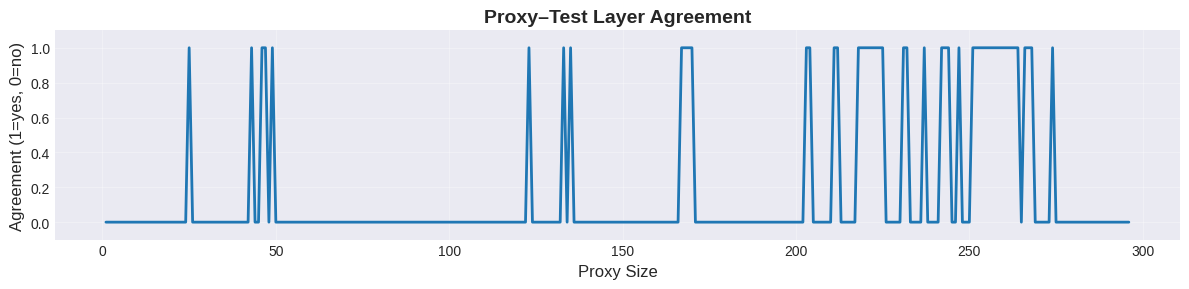


Agreement Statistics:
  Overall agreement rate: 16.55%
  Agreement count: 49 / 296
  First agreement at proxy size: 25


In [39]:
# Plot agreement between proxy and test selections
agreement = np.array(proxy_best_layers_scalar) == np.array(test_best_layers_scalar)

plt.figure(figsize=(12, 3))
plt.plot(proxy_sizes[:len(agreement)], agreement.astype(int), linewidth=2)
plt.xlabel("Proxy Size", fontsize=12)
plt.ylabel("Agreement (1=yes, 0=no)", fontsize=12)
plt.title("Proxy–Test Layer Agreement", fontsize=14, fontweight='bold')
plt.ylim(-0.1, 1.1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate agreement statistics
agreement_rate = agreement.mean()
print(f"\nAgreement Statistics:")
print(f"  Overall agreement rate: {agreement_rate:.2%}")
print(f"  Agreement count: {agreement.sum()} / {len(agreement)}")
print(f"  First agreement at proxy size: {proxy_sizes[np.where(agreement)[0][0]] if agreement.any() else 'None'}")

## 13. Save Results

Save all analysis results and figures for future reference.

In [40]:
# Create output directories
import os
os.makedirs('./figures', exist_ok=True)
os.makedirs('./results', exist_ok=True)

# Save bar charts for ALL 4 metrics
for metric_key in ['rewrite_acc', 'locality_acc', 'fluency', 'overall']:
    if metric_key in proxy_means:
        fig, ax = plt.subplots(figsize=(14, 5))
        
        proxy_values = proxy_means[metric_key].numpy()
        test_values = test_means[metric_key].numpy()
        
        x = np.arange(n_layers)
        width = 0.35
        
        ax.bar(x - width/2, proxy_values, width, label='Proxy Set', alpha=0.8)
        ax.bar(x + width/2, test_values, width, label='Test Set', alpha=0.8)
        
        ax.set_xlabel('Layer', fontsize=12)
        ax.set_ylabel('Score', fontsize=12)
        
        metric_name = analysis[metric_key]['name'] if metric_key in analysis else metric_key
        correlation = analysis[metric_key]['correlation'] if metric_key in analysis else 0
        
        # Add note for fluency
        title_suffix = " (lower is better)" if metric_key == 'fluency' else ""
        ax.set_title(f'{metric_name}{title_suffix} - Correlation: {correlation:.3f}',
                    fontsize=14, fontweight='bold')
        ax.legend(loc='best', fontsize=10)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_xticks(range(0, n_layers, 2))
        ax.set_xticklabels(range(0, n_layers, 2), fontsize=9)
        
        plt.tight_layout()
        plt.savefig(f'./figures/{metric_key}_comparison.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"Saved: figures/{metric_key}_comparison.png")

# Save all results as torch tensors
results_to_save = {
    'results': results,
    'proxy_means': proxy_means,
    'test_means': test_means,
    'analysis': analysis,
    'proxy_indices': proxy_indices,
    'test_indices': test_indices,
    'n_samples': n_samples,
    'n_layers': n_layers,
    'proxy_best_layers_scalar': proxy_best_layers_scalar,
    'test_best_layers_scalar': test_best_layers_scalar,
    'proxy_sizes': proxy_sizes
}

torch.save(results_to_save, './results/wikibio_golden_layer_analysis.pt')
print("Saved: results/wikibio_golden_layer_analysis.pt")

# Save detailed CSV with ALL 4 layer performances
detailed_data = []
for layer in range(n_layers):
    row = {'Layer': layer}
    for metric_key in ['rewrite_acc', 'locality_acc', 'fluency', 'overall']:
        if metric_key in proxy_means:
            row[f'{metric_key}_proxy'] = proxy_means[metric_key][layer].item()
            row[f'{metric_key}_test'] = test_means[metric_key][layer].item()
    detailed_data.append(row)

df_detailed = pd.DataFrame(detailed_data)
df_detailed.to_csv('./results/wikibio_layer_performance_detailed.csv', index=False)
print("Saved: results/wikibio_layer_performance_detailed.csv")

print("\nAll results saved successfully!")

Saved: figures/rewrite_acc_comparison.png
Saved: figures/locality_acc_comparison.png
Saved: figures/fluency_comparison.png
Saved: figures/overall_comparison.png
Saved: results/wikibio_golden_layer_analysis.pt
Saved: results/wikibio_layer_performance_detailed.csv

All results saved successfully!
